        # Lesson 7.6 · Machine-Learning Forecasting
        ### Lag features + Linear Regression, Random Forest, Gradient Boosting and XGBoost

        | | |
        |---|---|
        | ⏱️ **Time** | about 110 minutes |
        | 📚 **Before you start** | Lessons 7.1 – 7.5, scikit-learn basics from earlier phases |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Reframe forecasting as **supervised learning** on a leak-free feature table
- Explain, and fix, why tree models **cannot extrapolate trends** (predict *changes*, not levels)
- Fit **Ridge, Random Forest, Gradient Boosting and XGBoost** forecasters and tune them with **time-ordered cross-validation**
- Compare **direct** and **recursive** multi-step strategies
- Interpret models with **feature / permutation importance**

> 🌾 **The story so far.** The cooperative's data analyst asks: *"Can't we just throw XGBoost at it?"* You can, but only if you respect time. Today we learn how to do that, and discover when the fancy model *loses*.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

import inspect
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · Forecasting as a table problem

Machine-learning models know nothing about time. They see a **table**: rows of features → a target. Our job is to *encode time into columns*:

| Idea | Column examples | Intuition |
|---|---|---|
| **Momentum** | `mom_4` = log price now − 4 weeks ago | trends persist for a while |
| **Mean reversion** | `dev_52` = log price − 1-year average | extremes pull back |
| **Volatility** | `vol_8` = std of recent weekly returns | calm vs jumpy regime |
| **Calendar** | sin/cos of the *target* date | harvest seasons |
| **Drivers** | rainfall now, 4 and 8 weeks ago | supply signal |

Our library function `ag.make_origin_table(y, h, exog)` builds this table. Read its docstring: it is the contract:

In [2]:
y = ag.price_series("tomato", "Central", "W")
rain9 = ag.load_weather().set_index("date")["rainfall_mm"].resample("W").sum().reindex(y.index).rolling(9, min_periods=1).sum()
EXOG = pd.DataFrame({"rain_9w": rain9})

print(ag.make_origin_table.__doc__)
tab4 = ag.make_origin_table(y, h=4, exog=EXOG)
print("rows:", len(tab4), "| usable for training:", len(tab4.dropna()), "| columns:", list(tab4.columns))
tab4.dropna().head(3).round(3)


    Supervised table for DIRECT h-step forecasting of a positive price series.

    Row t is a forecast ORIGIN: every feature uses information up to and including t only.
      target    = log(y_{t+h}) - log(y_t)         the log-CHANGE over the next h steps  (NaN for the last h rows)
      mom_k     = log(y_t) - log(y_{t-k})          momentum over the last k steps
      vol_8     = std of the last 8 one-step log-returns
      dev_52    = log(y_t) - mean(log y over the last 52 steps)    (mean-reversion signal)
      tsin/tcos = calendar position of the TARGET date (known in advance)
      <exog>, <exog>_lag4, <exog>_lag8 = observed drivers (e.g. rainfall) at the origin
    Predicting a CHANGE instead of a LEVEL lets tree models handle trending prices (they cannot extrapolate levels).
    
rows: 523 | usable for training: 467 | columns: ['target', 'mom_1', 'mom_2', 'mom_3', 'mom_4', 'mom_8', 'mom_13', 'mom_26', 'mom_52', 'vol_8', 'dev_52', 'tsin', 'tcos', 'rain_9w', 'rain_9w_lag4', 'rai

,target,mom_1,mom_2,mom_3,mom_4,mom_8,mom_13,mom_26,mom_52,vol_8,dev_52,tsin,tcos,rain_9w,rain_9w_lag4,rain_9w_lag8
date,,,,,,,,,,,,,,,,
2016-01-03,0.187,0.026,0.085,0.110,-0.003,-0.122,-0.164,0.200,-0.209,0.060,-0.137,0.508,0.861,226.9,453.9,610.4
2016-01-10,0.219,0.012,0.038,0.096,0.122,-0.144,-0.240,0.198,-0.191,0.057,-0.121,0.608,0.794,188.5,445.0,525.4
2016-01-17,0.338,-0.003,0.009,0.036,0.094,-0.082,-0.252,0.237,-0.170,0.054,-0.120,0.699,0.715,141.3,387.0,479.2


Two design decisions worth savouring:

1. **Row = forecast origin.** Row *t* only contains information available at *t*; its target is the *future* log-change `log y_{t+h} − log y_t`.
   The final *h* rows have no target yet: those are the rows we will *predict*.
2. **Target = change, not level.** Why? Let's see what happens if we don't: a live demonstration.

## 2 · The extrapolation trap
Random forests and boosted trees predict by averaging training targets in leaves. They can **never output a value outside the range of targets they saw**.
Prices trend upward, so the *future* level is, by construction, *outside* the training range. Watch:

RF on price LEVELS  MAE = 13.16   |   naive MAE = 6.48


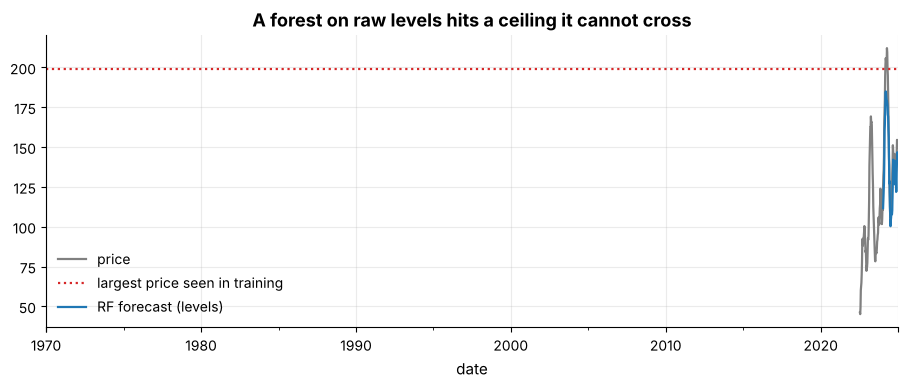

In [3]:
cut = len(y) - 52                                          # hold out the final year; one-step-ahead forecasts
lv = ag.make_ts_features(y, lags=(1, 2, 3, 4, 52), roll_windows=(4, 13)).dropna()
tr_lv, te_lv = lv[lv.index < y.index[cut]], lv[lv.index >= y.index[cut]]

rf_level = RandomForestRegressor(300, min_samples_leaf=2, random_state=0, n_jobs=-1).fit(tr_lv.drop(columns="y"), tr_lv["y"])
pred_level = rf_level.predict(te_lv.drop(columns="y"))
actual_te = te_lv["y"]
mae_level = ag.mae(actual_te, pred_level)
mae_naive_1 = ag.mae(actual_te, te_lv["lag_1"])
print(f"RF on price LEVELS  MAE = {mae_level:.2f}   |   naive MAE = {mae_naive_1:.2f}")

fig, ax = plt.subplots(figsize=(11, 3.8))
y.iloc[-130:].plot(ax=ax, color="gray", label="price")
ax.axhline(tr_lv["y"].max(), color="tab:red", ls=":", label="largest price seen in training")
pd.Series(pred_level, index=te_lv.index).plot(ax=ax, color="tab:blue", label="RF forecast (levels)")
ax.legend(); ax.set_title("A forest on raw levels hits a ceiling it cannot cross"); plt.show()

> 🤔 **Pause and think.** How would you change the *target* so the model never has to predict a number outside what it has seen?
>
> <details><summary>Click to reveal the answer</summary>
>
> Predict the **change** (e.g. the log-return over *h* weeks). Changes are roughly stationary (a +5 % move looks the same at price 60 or price 150) so the future change *is* inside the training range. Then price forecast = current price × exp(predicted change).
>
> </details>

---
### 🧩 Exercise 1: Predict the change, not the level  ⭐⭐

Repeat the one-step-ahead experiment, but with **log-change targets**:
1. `t1 = ag.make_origin_table(y, 1, EXOG)` (provided).
2. Training rows: origins up to `y.index[cut-2]` (so each training target lies before the test year), dropping NaNs → `tr`.
3. Test rows: origins from `y.index[cut-1]` to `y.index[-2]` → `te` (52 rows; test targets are the final 52 prices).
4. Fit a Random Forest (300 trees, `min_samples_leaf=2`, `random_state=0`) on `tr`, predict the change for `te`,
   convert to prices with `y.loc[te.index] * np.exp(pred)` → `price_pred`.
5. `mae_change` = MAE against `y.iloc[cut:]`. Set `change_wins = mae_change < mae_level`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`tr = t1.loc[:y.index[cut-2]].dropna()` and `te = t1.loc[y.index[cut-1]:y.index[-2]]`. Features are `.drop(columns='target')`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`rf = RandomForestRegressor(300, min_samples_leaf=2, random_state=0, n_jobs=-1).fit(tr.drop(columns='target'), tr['target'])`

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`pred = rf.predict(te.drop(columns='target'))`; `price_pred = y.loc[te.index].to_numpy() * np.exp(pred)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
t1 = ag.make_origin_table(y, 1, EXOG)
tr = None
te = None
price_pred = None
mae_change = None
change_wins = None

In [ ]:
try:
    ag.check("52 test rows", te is not None and len(te) == 52)
    ag.check("price_pred is in price units", price_pred is not None and 30 < np.mean(price_pred) < 400)
    ag.check("predicting changes beats predicting levels", change_wins is True, "target = log y_(t+h) - log y_t")
    ag.check("and it is competitive with naive (within 25 %)", mae_change is not None and mae_change < 1.25 * mae_naive_1)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 3 · Linear regression with lag features (the underrated champion)

$$\widehat{\Delta \log y}_{t\to t+h} = \beta_0 + \beta_1\,\text{mom}_1 + \beta_2\,\text{mom}_4 + \dots + \beta_k\,\text{dev}_{52}$$

A linear model is fast, can extrapolate, and its coefficients tell a story. With only ~450 rows and many correlated features we add **Ridge**
(an L2 penalty $\alpha\sum\beta_j^2$ that shrinks coefficients and stabilises them) and **standardise** features so the penalty is fair.

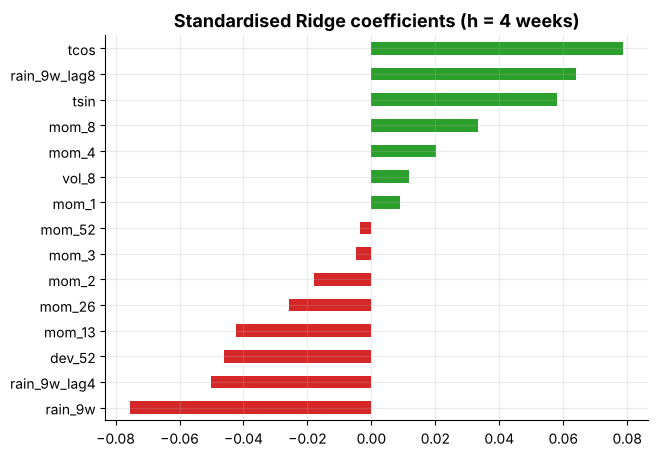

In [6]:
rows4 = tab4.dropna()
X4, y4 = rows4.drop(columns="target"), rows4["target"]
ridge4 = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(X4, y4)
coefs = pd.Series(ridge4[-1].coef_, index=X4.columns).sort_values()
ax = coefs.plot.barh(figsize=(7, 5), color=["tab:red" if c < 0 else "tab:green" for c in coefs]); ax.set_title("Standardised Ridge coefficients (h = 4 weeks)"); plt.show()

A strongly **negative `dev_52`** coefficient = mean reversion (prices far above their yearly average tend to fall back).
The calendar terms capture the harvest cycle. *(Fitted on all data here for interpretation only; never evaluate on the data you fit.)*

### Choosing α without cheating: time-ordered cross-validation
`KFold` shuffles; **`TimeSeriesSplit`** keeps order: each fold trains on the past and validates on the block right after it.

In [7]:
gs = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
                  cv=TimeSeriesSplit(n_splits=5), scoring="neg_mean_absolute_error")
gs.fit(X4, y4)
print("best alpha:", gs.best_params_)
pd.DataFrame(gs.cv_results_)[["param_ridge__alpha", "mean_test_score"]].assign(MAE=lambda d: -d.mean_test_score).round(4)

best alpha: {'ridge__alpha': 10}


,param_ridge__alpha,mean_test_score,MAE
0,0.01,-0.1072,0.1072
1,0.10,-0.1018,0.1018
2,1.00,-0.0885,0.0885
3,10.00,-0.0829,0.0829
4,100.00,-0.0865,0.0865
5,1000.00,-0.1216,0.1216


---
### 🧩 Exercise 2: Tune the regularisation properly  ⭐⭐

Run your own time-ordered grid search on the **h = 8** table:
`rows8 = ag.make_origin_table(y, 8, EXOG).dropna()`. Use `TimeSeriesSplit(n_splits=4)`,
a Ridge pipeline (StandardScaler + Ridge) and `alpha in [0.1, 1, 10, 100, 1000]`, scoring by negative MAE.
Store the best alpha in `best_alpha_8` and the best (positive) CV MAE in `best_cv_mae`.

<details><summary>💡 Hint 1: gentle nudge</summary>

Reuse the pattern from the cell above: `GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {'ridge__alpha': [...]}, cv=TimeSeriesSplit(4), scoring='neg_mean_absolute_error')`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Fit with `.fit(rows8.drop(columns='target'), rows8['target'])`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`best_alpha_8 = gs8.best_params_['ridge__alpha']`; `best_cv_mae = -gs8.best_score_`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
rows8 = ag.make_origin_table(y, 8, EXOG).dropna()
best_alpha_8 = None
best_cv_mae = None

In [ ]:
try:
    ag.check("alpha is from the grid", best_alpha_8 in [0.1, 1, 10, 100, 1000])
    ag.check("CV MAE is a small positive number (log-change units)", best_cv_mae is not None and 0 < best_cv_mae < 0.5)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 4 · Random Forest

A forest averages hundreds of decision trees, each trained on a random *bootstrap* of rows and a random subset of features. Averaging cancels each tree's quirks.

| Hyper-parameter | Effect | Typical range |
|---|---|---|
| `n_estimators` | more trees = more stable (diminishing returns) | 200 – 1000 |
| `max_depth` | shallower = smoother, less overfit | 4 – 12 or `None` |
| `min_samples_leaf` | bigger = smoother; **crucial for noisy series** | 2 – 20 |
| `max_features` | decorrelates trees | 0.3 – 1.0 |

**Strengths:** nonlinear, hardly needs tuning, robust to outliers. **Weaknesses:** can't extrapolate, no notion of order, heavier than linear.

validation MAE (log-change): 0.0739 | predict-zero baseline: 0.1285


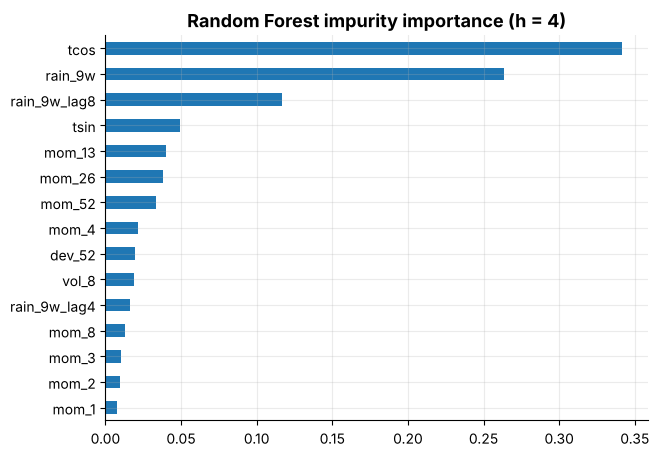

In [10]:
cut4 = int(len(rows4) * 0.8)
Xt, yt, Xv, yv = X4.iloc[:cut4], y4.iloc[:cut4], X4.iloc[cut4:], y4.iloc[cut4:]
rf_h4 = RandomForestRegressor(300, min_samples_leaf=3, random_state=0, n_jobs=-1).fit(Xt, yt)
print("validation MAE (log-change):", round(ag.mae(yv, rf_h4.predict(Xv)), 4), "| predict-zero baseline:", round(ag.mae(yv, np.zeros(len(yv))), 4))
imp = pd.Series(rf_h4.feature_importances_, index=X4.columns).sort_values()
imp.plot.barh(figsize=(7, 5), title="Random Forest impurity importance (h = 4)"); plt.show()

> ⚠️ **Common pitfall.** Built-in *impurity* importance is biased toward features with many distinct values and is computed on the **training** data. **Permutation importance** (shuffle one column of *validation* data, see how much the error rises) is more honest.

---
### 🧩 Exercise 3: Permutation importance  ⭐⭐

Using the fitted forest `rf_h4` and the chronological validation set `Xv, yv`, compute permutation importance with
`n_repeats=15`, `random_state=0`, `scoring="neg_mean_absolute_error"`. Store the mean importances as a Series `perm`
(index = feature names) sorted descending, and the name of the single most important feature in `top_feature`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`r = permutation_importance(rf_h4, Xv, yv, n_repeats=15, random_state=0, scoring='neg_mean_absolute_error')`

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`r.importances_mean` is an array aligned with the columns of `Xv`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`perm = pd.Series(r.importances_mean, index=Xv.columns).sort_values(ascending=False)`; `top_feature = perm.index[0]`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
perm = None
top_feature = None

In [ ]:
try:
    ag.check("one importance per feature", perm is not None and len(perm) == Xv.shape[1])
    ag.check("sorted descending", perm is not None and perm.is_monotonic_decreasing)
    ag.check("top_feature is a real column", top_feature in Xv.columns)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 5 · Gradient Boosting & XGBoost

Instead of averaging independent trees, **boosting** builds trees *in sequence*, each one fitted to the **residual errors** of the ensemble so far:

$$F_m(x) = F_{m-1}(x) + \eta\, h_m(x)$$

with *learning rate* $\eta$ (small = careful steps, needs more trees). **XGBoost** adds regularisation, second-order gradients, fast histogram splits, and native handling of missing values.

| Hyper-parameter | Effect | Typical |
|---|---|---|
| `learning_rate` (η) | shrinks each tree's contribution | 0.02 – 0.1 |
| `n_estimators` | number of boosting rounds: **pair with η**; use early stopping | 100 – 1000 |
| `max_depth` | complexity of each tree | **2 – 5** for small data |
| `subsample`, `colsample_bytree` | row/column sampling = regularisation | 0.6 – 0.9 |
| `reg_lambda`, `min_child_weight` | penalise complex trees | 1 – 10 |

Boosting can **overfit** (unlike a forest, more trees isn't always safe). The cure is **early stopping** on a *chronological* validation block: stop adding trees when validation error stops improving.

In [13]:
xgb = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                   early_stopping_rounds=25, random_state=0, n_jobs=1)
xgb.fit(Xt, yt, eval_set=[(Xv, yv)], verbose=False)
print("best round:", xgb.best_iteration, "of 600 | validation MAE:", round(ag.mae(yv, xgb.predict(Xv)), 4))

best round: 36 of 600 | validation MAE: 0.0651


---
### 🧩 Exercise 4: Early stopping  ⭐⭐

Train an `XGBRegressor` on `Xt, yt` with `n_estimators=1000`, `learning_rate=0.03`, `max_depth=2`, `subsample=0.8`,
`early_stopping_rounds=30`, `random_state=0`, `n_jobs=1`, validating on `(Xv, yv)`. Store the model in `xgb2`,
its `best_iteration` in `best_round`, and `stopped_early = best_round < 999`.

<details><summary>💡 Hint 1: gentle nudge</summary>

Early stopping is set in the constructor: `XGBRegressor(..., early_stopping_rounds=30)`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`xgb2.fit(Xt, yt, eval_set=[(Xv, yv)], verbose=False)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`best_round = int(xgb2.best_iteration)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
xgb2 = None
best_round = None
stopped_early = None

In [ ]:
try:
    ag.check("model is trained", xgb2 is not None and hasattr(xgb2, "best_iteration"))
    ag.check("best_round is an int", isinstance(best_round, int))
    ag.check("it stopped early (validation stopped improving)", stopped_early is True)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 6 · Multi-step strategies: direct vs recursive

To forecast *h* weeks ahead:

| Strategy | How | Pros | Cons |
|---|---|---|---|
| **Recursive** | one 1-step model; feed its own predictions back as inputs | 1 model; any horizon | **errors compound**; needs all features re-computable |
| **Direct** | a *separate* model per horizon (what `make_origin_table(y, h)` does) | no compounding; features can differ by h | *h* models to train |
| **Multi-output** | one model, vector target | shared learning | fewer off-the-shelf options |

Let's implement the recursive version for a Ridge AR-type model and race it against the direct one.

In [16]:
def recursive_ridge(train, h, n_lags=4):
    lr = np.log(train).diff().dropna()
    X = np.column_stack([lr.shift(k) for k in range(1, n_lags + 1)])[n_lags:]       # lags of the returns
    t = lr.to_numpy()[n_lags:]
    model = make_pipeline(StandardScaler(), Ridge(10)).fit(X, t)
    window = list(lr.iloc[-n_lags:][::-1])                                          # most recent first
    path, level = [], float(train.iloc[-1])
    for _ in range(h):
        r = float(model.predict(np.array([window]))[0])
        level *= np.exp(r); path.append(level)
        window = [r] + window[:-1]                                                  # slide: newest prediction enters
    return np.array(path)

cmp_models = {"naive": ag.naive_forecast, "recursive Ridge (AR on returns)": recursive_ridge,
              "direct Ridge (full features)": ag.direct_ml_forecaster(lambda: make_pipeline(StandardScaler(), Ridge(10)), EXOG)}
cmp = {n: ag.walk_forward(y, f, initial=300, horizon=8, step=8) for n, f in cmp_models.items()}
pd.DataFrame({n: r.groupby("h").apply(lambda d: ag.mae(d.actual, d.forecast)) for n, r in cmp.items()}).round(2)

,naive,recursive Ridge (AR on returns),direct Ridge (full features)
h,,,
1,4.84,3.33,3.63
2,8.04,5.62,5.92
3,12.98,8.41,6.75
4,17.22,13.25,8.11
5,20.46,16.78,8.70
6,24.20,20.68,10.69
7,27.06,24.29,11.46
8,30.71,28.67,13.52


The recursive AR model has *no calendar and no rain* (it can only extrapolate momentum) so it fades quickly. The direct model, free to use the season and the drivers *at each horizon*, keeps its edge.
(Part of that gap is information, not strategy; in a controlled comparison with identical features, direct usually wins on long horizons because it avoids error compounding.)

---
### 🧩 Exercise 5: Write the recursive loop  ⭐⭐⭐

Implement `recursive_price_path(model, last_returns, last_price, h)`:
- `last_returns` is a list of the most recent log-returns, **oldest → newest** (length 4).
- Repeat *h* times: predict the next return with `model.predict([window])[0]`; append the new price
  (`price *= exp(r)`) to the path; slide the window (drop the oldest return, add the new one at the end).
- Return the prices as a NumPy array.
A pretend trained model `fake` (`r_next = 0.001 + 0.5·r[-1] + 0.2·r[-2]`) is provided.

<details><summary>💡 Hint 1: gentle nudge</summary>

`window = list(last_returns)`; `price = last_price`; `path = []`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Inside the loop: `r = model.predict([window])[0]`; `price = price * np.exp(r)`; `path.append(price)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Slide: `window = window[1:] + [r]`. Finally `return np.array(path)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
class FakeModel:
    def predict(self, X):
        X = np.asarray(X, float)
        return 0.001 + 0.5 * X[:, -1] + 0.2 * X[:, -2]
fake = FakeModel()

def recursive_price_path(model, last_returns, last_price, h):
    return None

path = recursive_price_path(fake, [0.01, -0.02, 0.03, 0.04], 100.0, 3)

In [ ]:
try:
    r1 = 0.001 + 0.5 * 0.04 + 0.2 * 0.03
    r2 = 0.001 + 0.5 * r1 + 0.2 * 0.04
    r3 = 0.001 + 0.5 * r2 + 0.2 * r1
    expected = 100 * np.exp(np.cumsum([r1, r2, r3]))
    ag.check("returns 3 prices", path is not None and len(path) == 3)
    ag.check("matches the hand calculation", path is not None and np.allclose(path, expected),
             "each prediction must become the newest element of the window")
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 7 · The big comparison: walk-forward, horizons 1–8

Every model is **refit from scratch at each origin** using only data up to that origin (that's what `direct_ml_forecaster` does).
First window = 300 weeks; origins every 8 weeks (a compromise between realism and runtime).

In [19]:
models = {
    "naive": ag.naive_forecast,
    "seasonal naive": ag.seasonal_naive_forecast,
    "Ridge": ag.direct_ml_forecaster(lambda: make_pipeline(StandardScaler(), Ridge(10)), EXOG),
    "Random Forest": ag.direct_ml_forecaster(lambda: RandomForestRegressor(100, min_samples_leaf=3, random_state=0, n_jobs=-1), EXOG),
    "Gradient Boosting": ag.direct_ml_forecaster(lambda: GradientBoostingRegressor(n_estimators=150, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=0), EXOG),
    "XGBoost": ag.direct_ml_forecaster(lambda: XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=1), EXOG),
}
ml_res = {n: ag.walk_forward(y, f, initial=300, horizon=8, step=8) for n, f in models.items()}
ag.score_table(ml_res, y_train=y.iloc[:300])

,MAE,RMSE,MAPE,MASE
Ridge,8.599,11.342,8.340,2.069
XGBoost,9.666,13.127,9.690,2.326
Gradient Boosting,9.701,13.288,9.697,2.335
Random Forest,9.963,13.630,9.899,2.398
naive,18.188,26.746,17.520,4.377
seasonal naive,22.499,26.757,19.669,5.415


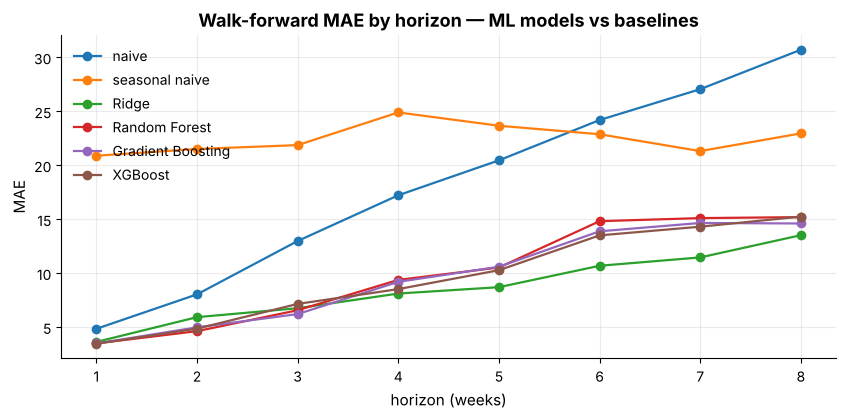

In [20]:
by_h = pd.DataFrame({n: r.groupby("h").apply(lambda d: ag.mae(d.actual, d.forecast)) for n, r in ml_res.items()})
ax = by_h.plot(marker="o", figsize=(10, 4.2)); ax.set(xlabel="horizon (weeks)", ylabel="MAE", title="Walk-forward MAE by horizon: ML models vs baselines"); plt.show()

### What to take away (this is the real lesson)
1. **Every ML model crushes the naive baseline** beyond h = 2: once they model *changes* with calendar and rain features.
2. **The simple Ridge model is at least as good as the tree ensembles** here. With ~450 rows and a smooth, trending target, flexibility buys little.
   Complexity must *earn* its place; this is why you always include a linear baseline.
3. Trees and boosting shine with **more data, more series, interactions and thresholds** (e.g. pooling all 12 market-crop series into one model; try it in the capstone!).
4. Differences among the three tree models are small relative to the noise in 30 origins: *don't over-interpret a 3 % gap.*

## 🎓 Mini-quiz
1. Why do we compute rolling features on `shift`ed data? 2. Why does `TimeSeriesSplit` never put a fold's validation block *before* its training block?
3. Your XGBoost's best round is 12 out of 600. What does that suggest?

<details><summary>Answers</summary>

1. To avoid including the value being predicted in its own features. 2. Training on the future to predict the past is leakage. 3. The learning rate is too high or the data are too noisy for a flexible model: lower η, shallower trees, more regularisation, or go back to a simpler model.
</details>

        ---
        ## 🧾 Recap
        - Encode time into columns (momentum, mean-reversion, volatility, calendar, lagged drivers): **every feature known at the origin**.
- **Predict changes, not levels**: tree models cannot extrapolate trends.
- Tune with **TimeSeriesSplit**; use **early stopping** on a chronological validation block.
- **Direct** (one model per horizon) vs **recursive** (feed predictions back): know the compounding-error trade-off.
- Always keep a **linear baseline**: on small data it often wins.
- Interpret with **permutation importance** on validation data.

**Next up:** Lesson 7.7: deep-learning forecasting: windows, RNN, LSTM, GRU and a small Transformer (a first look; Phase 8 builds the foundations).